In [13]:
from io import BytesIO

import pandas as pd
from google.colab import files

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Hãy chọn đúng một tệp CSV.")

ten_tep, noi_dung = next(iter(uploaded.items()))

if not ten_tep.lower().endswith(".csv"):
    raise ValueError("Hãy giải nén archive.zip rồi chọn tệp CSV bên trong.")

df = pd.read_csv(BytesIO(noi_dung), encoding="utf-8-sig")

if "Attrition" not in df.columns:
    raise ValueError("Tệp này thiếu cột Attrition. Hãy chọn đúng CSV của Đề tài 13.")

print("Số dòng, số cột:", df.shape)
print("Số nhân viên theo nhãn Attrition:")
print(df["Attrition"].value_counts())

Saving WA_Fn-UseC_-HR-Employee-Attrition.csv to WA_Fn-UseC_-HR-Employee-Attrition (1).csv
Số dòng, số cột: (1470, 35)
Số nhân viên theo nhãn Attrition:
Attrition
No     1233
Yes     237
Name: count, dtype: int64


Số ô bị thiếu: 0
Số dòng trùng hoàn toàn: 0
Các cột chỉ có một giá trị: ['EmployeeCount', 'Over18', 'StandardHours']


,Số nhân viên,Tỷ lệ (%)
Attrition,,
No,1233,83.88
Yes,237,16.12


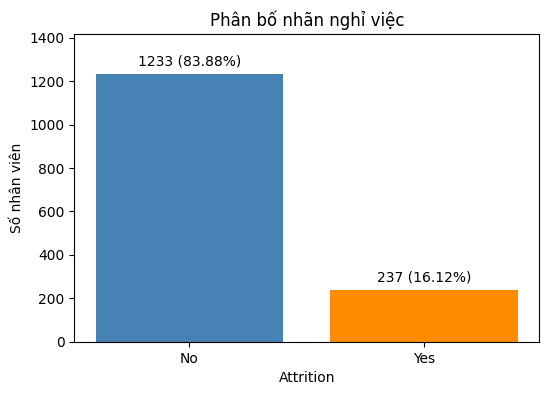

In [14]:
import matplotlib.pyplot as plt

# Kiểm tra chất lượng dữ liệu
print("Số ô bị thiếu:", df.isna().sum().sum())
print("Số dòng trùng hoàn toàn:", df.duplicated().sum())

cot_hang = df.columns[df.nunique(dropna=False).eq(1)].tolist()
print("Các cột chỉ có một giá trị:", cot_hang)

# Đếm số lượng và tính tỷ lệ của từng lớp
so_luong = df["Attrition"].value_counts().reindex(["No", "Yes"])
ty_le = (so_luong / len(df) * 100).round(2)

display(pd.DataFrame({
    "Số nhân viên": so_luong,
    "Tỷ lệ (%)": ty_le
}))

# Vẽ biểu đồ phân bố nhãn
fig, ax = plt.subplots(figsize=(6, 4))
cot = ax.bar(so_luong.index, so_luong.values, color=["steelblue", "darkorange"])
ax.bar_label(cot, labels=[f"{n} ({p:.2f}%)" for n, p in zip(so_luong, ty_le)],
             padding=4)
ax.set_title("Phân bố nhãn nghỉ việc")
ax.set_xlabel("Attrition")
ax.set_ylabel("Số nhân viên")
ax.set_ylim(0, so_luong.max() * 1.15)
plt.show()

In [15]:
from sklearn.model_selection import train_test_split

# X chứa các cột dùng để dự đoán
X = df.drop(columns=["Attrition", "EmployeeNumber", *cot_hang])

# y là nhãn cần dự đoán: 0 = không nghỉ, 1 = nghỉ việc
y = df["Attrition"].map({"No": 0, "Yes": 1})

# Chia 80% để huấn luyện và 20% để kiểm thử
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Tập huấn luyện (số dòng, số cột):", X_train.shape)
print("Tập kiểm thử (số dòng, số cột):", X_test.shape)

bang_chia = pd.DataFrame({
    "Huấn luyện": y_train.value_counts(),
    "Kiểm thử": y_test.value_counts()
}).sort_index().rename(index={0: "No (0)", 1: "Yes (1)"})

display(bang_chia)

Tập huấn luyện (số dòng, số cột): (1176, 30)
Tập kiểm thử (số dòng, số cột): (294, 30)


,Huấn luyện,Kiểm thử
Attrition,,
No (0),986,247
Yes (1),190,47


In [16]:
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def tao_dac_trung_B(bang):
    bang_moi = bang.copy()

    cac_ty_le = {
        "CompanyTenureShare": ("YearsAtCompany", "TotalWorkingYears"),
        "RoleTenureShare": ("YearsInCurrentRole", "YearsAtCompany"),
        "PromotionLagShare": ("YearsSinceLastPromotion", "YearsAtCompany"),
    }

    for ten, (tu_so, mau_so) in cac_ty_le.items():
        mau = bang[mau_so]
        ty_le = bang[tu_so] / mau.where(mau != 0)
        bang_moi[ten] = ty_le.mask(mau == 0, 0)

    return bang_moi


def tao_tien_xu_ly(chuan_hoa=False):
    buoc_so = [("dien_thieu", SimpleImputer(strategy="median"))]
    if chuan_hoa:
        buoc_so.append(("chuan_hoa", StandardScaler()))

    buoc_danh_muc = Pipeline([
        ("dien_thieu", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    return ColumnTransformer([
        ("so", Pipeline(buoc_so), make_column_selector(dtype_include="number")),
        ("danh_muc", buoc_danh_muc, make_column_selector(dtype_exclude="number")),
    ])


# Chạy thử hai luồng trên tập huấn luyện
kiem_tra_A = tao_tien_xu_ly(chuan_hoa=True).fit_transform(X_train)
kiem_tra_B = tao_tien_xu_ly(chuan_hoa=True).fit_transform(
    tao_dac_trung_B(X_train)
)

print("Luồng A sau tiền xử lý:", kiem_tra_A.shape)
print("Luồng B sau tiền xử lý:", kiem_tra_B.shape)

Luồng A sau tiền xử lý: (1176, 51)
Luồng B sau tiền xử lý: (1176, 54)


In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import FunctionTransformer
from sklearn.tree import DecisionTreeClassifier

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Baseline luôn dự đoán lớp phổ biến nhất
baseline = DummyClassifier(strategy="most_frequent")
f1_baseline = cross_val_score(
    baseline, X_train, y_train, cv=cv, scoring="f1"
).mean()
baseline.fit(X_train, y_train)

mo_hinh_da_huan_luyen = {"Baseline": baseline}
dong_ket_qua = [{
    "Phương án": "Baseline",
    "F1 CV": f1_baseline,
    "Tham số tốt nhất": "most_frequent",
}]

thi_nghiem = [
    (
        "K-NN", KNeighborsClassifier(metric="minkowski", p=2), True,
        {
            "model__n_neighbors": [3, 5, 9, 15, 25],
            "model__weights": ["uniform", "distance"],
        },
    ),
    (
        "Cây quyết định", DecisionTreeClassifier(random_state=42), False,
        {
            "model__max_depth": [3, 5, 8, None],
            "model__min_samples_leaf": [1, 5, 15],
            "model__class_weight": [None, "balanced"],
        },
    ),
]

for ten, mo_hinh, chuan_hoa, luoi_tham_so in thi_nghiem:
    for luong in ["A", "B"]:
        ten_phuong_an = f"{ten} {luong}"
        tao_dac_trung = (
            FunctionTransformer(tao_dac_trung_B) if luong == "B" else "passthrough"
        )

        quy_trinh = Pipeline([
            ("dac_trung", tao_dac_trung),
            ("tien_xu_ly", tao_tien_xu_ly(chuan_hoa=chuan_hoa)),
            ("model", mo_hinh),
        ])

        tim_kiem = GridSearchCV(
            quy_trinh, luoi_tham_so, cv=cv, scoring="f1", error_score="raise"
        )
        tim_kiem.fit(X_train, y_train)

        mo_hinh_da_huan_luyen[ten_phuong_an] = tim_kiem.best_estimator_
        dong_ket_qua.append({
            "Phương án": ten_phuong_an,
            "F1 CV": tim_kiem.best_score_,
            "Tham số tốt nhất": {
                khoa.split("__", 1)[1]: gia_tri
                for khoa, gia_tri in tim_kiem.best_params_.items()
            },
        })

bang_cv = pd.DataFrame(dong_ket_qua).sort_values("F1 CV", ascending=False)
phuong_an_tot_nhat = bang_cv.iloc[0]["Phương án"]

with pd.option_context("display.max_colwidth", None):
    display(bang_cv.round({"F1 CV": 4}))

print("Phương án được chọn theo F1 CV:", phuong_an_tot_nhat)

,Phương án,F1 CV,Tham số tốt nhất
4,Cây quyết định B,0.4068,"{'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 5}"
3,Cây quyết định A,0.3905,"{'class_weight': None, 'max_depth': 8, 'min_samples_leaf': 5}"
2,K-NN B,0.2675,"{'n_neighbors': 3, 'weights': 'uniform'}"
1,K-NN A,0.2559,"{'n_neighbors': 3, 'weights': 'uniform'}"
0,Baseline,0.0000,most_frequent


Phương án được chọn theo F1 CV: Cây quyết định B


,Accuracy,Precision,Recall,F1
Phương án,,,,
Baseline,0.8401,0.0000,0.0000,0.0000
K-NN A,0.8299,0.4286,0.1915,0.2647
K-NN B,0.8231,0.3529,0.1277,0.1875
Cây quyết định A,0.8095,0.3902,0.3404,0.3636
Cây quyết định B,0.8027,0.3778,0.3617,0.3696


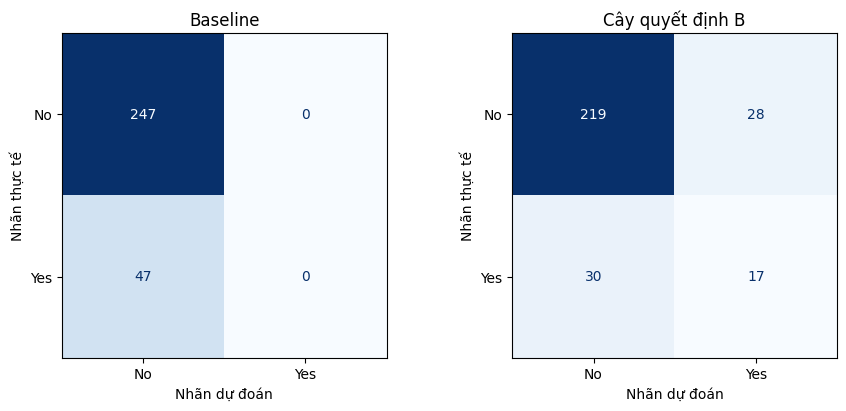

In [7]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

du_doan_test = {}
ket_qua_test = []

for ten, mo_hinh in mo_hinh_da_huan_luyen.items():
    du_doan = mo_hinh.predict(X_test)
    du_doan_test[ten] = du_doan

    ket_qua_test.append({
        "Phương án": ten,
        "Accuracy": accuracy_score(y_test, du_doan),
        "Precision": precision_score(y_test, du_doan, zero_division=0),
        "Recall": recall_score(y_test, du_doan, zero_division=0),
        "F1": f1_score(y_test, du_doan, zero_division=0),
    })

bang_test = pd.DataFrame(ket_qua_test).set_index("Phương án")
display(bang_test.round(4))

fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")

for ax, ten in zip(axes, ["Baseline", phuong_an_tot_nhat]):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        du_doan_test[ten],
        labels=[0, 1],
        display_labels=["No", "Yes"],
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set(title=ten, xlabel="Nhãn dự đoán", ylabel="Nhãn thực tế")

fig.savefig("ma_tran_nham_lan.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

# Ghép nhãn thực tế và nhãn dự đoán với các đặc trưng cần xem
cot_phan_tich = ["Age", "OverTime", "MonthlyIncome", "YearsAtCompany",
                 "JobSatisfaction"]
bang_du_doan = X_test[cot_phan_tich].copy()
bang_du_doan["Thực tế"] = y_test
bang_du_doan["Dự đoán"] = du_doan_test[phuong_an_tot_nhat]

# FN: thực tế nghỉ việc nhưng mô hình dự đoán không nghỉ
# FP: thực tế không nghỉ việc nhưng mô hình dự đoán nghỉ
fn = bang_du_doan["Thực tế"].eq(1) & bang_du_doan["Dự đoán"].eq(0)
fp = bang_du_doan["Thực tế"].eq(0) & bang_du_doan["Dự đoán"].eq(1)

bang_du_doan["Loại lỗi"] = "Đúng"
bang_du_doan.loc[fn, "Loại lỗi"] = "FN"
bang_du_doan.loc[fp, "Loại lỗi"] = "FP"

# Trong các ca nghỉ việc thực tế, đếm số bị bỏ sót theo tình trạng làm thêm
ca_nghi_viec = bang_du_doan.loc[bang_du_doan["Thực tế"].eq(1)].copy()
ca_nghi_viec["Bỏ sót"] = ca_nghi_viec["Loại lỗi"].eq("FN")

bang_bo_sot = (
    ca_nghi_viec.groupby("OverTime")["Bỏ sót"]
    .agg(["size", "sum"])
    .rename(columns={"size": "Số ca nghỉ việc", "sum": "Số ca bị bỏ sót"})
)
bang_bo_sot["Tỷ lệ bỏ sót (%)"] = (
    100 * bang_bo_sot["Số ca bị bỏ sót"] / bang_bo_sot["Số ca nghỉ việc"]
).round(2)

display(bang_bo_sot)

cac_ca_sai = bang_du_doan.loc[fn | fp].sort_index()
print("Mỗi loại lỗi lấy một ca minh họa. Chỉ số dòng bắt đầu từ 0.")
display(cac_ca_sai.groupby("Loại lỗi").head(1))

# Lưu kết quả để dùng khi viết báo cáo
bang_cv.to_csv("ket_qua_cv.csv", index=False, encoding="utf-8-sig")
bang_test.to_csv("ket_qua_kiem_thu.csv", encoding="utf-8-sig")
bang_bo_sot.to_csv("bo_sot_theo_lam_them.csv", encoding="utf-8-sig")
cac_ca_sai.to_csv("cac_ca_du_doan_sai.csv", index_label="Dong_CSV",
                 encoding="utf-8-sig")

ten_zip = "Nhom4_DeTai13_KetQua.zip"
with ZipFile(ten_zip, "w", compression=ZIP_DEFLATED) as goi:
    for ten_tep in ["ket_qua_cv.csv", "ket_qua_kiem_thu.csv",
                    "bo_sot_theo_lam_them.csv", "cac_ca_du_doan_sai.csv",
                    "ma_tran_nham_lan.png"]:
        goi.write(ten_tep)

files.download(ten_zip)

,Số ca nghỉ việc,Số ca bị bỏ sót,Tỷ lệ bỏ sót (%)
OverTime,,,
No,17,16,94.12
Yes,30,14,46.67


Mỗi loại lỗi lấy một ca minh họa. Chỉ số dòng bắt đầu từ 0.


,Age,OverTime,MonthlyIncome,YearsAtCompany,JobSatisfaction,Thực tế,Dự đoán,Loại lỗi
16,32,Yes,3298,6,2,0,1,FP
24,34,No,2960,4,1,1,0,FN


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,count,mean,std,min,25%,50%,75%,max,Ngoài ngưỡng IQR
Age,1176.0,37.00,9.18,18.0,30.0,36.0,43.0,60.0,0
MonthlyIncome,1176.0,6544.02,4653.74,1009.0,2948.0,5004.5,8420.5,19973.0,86
YearsAtCompany,1176.0,7.05,6.09,0.0,3.0,5.0,10.0,37.0,52
TotalWorkingYears,1176.0,11.36,7.80,0.0,6.0,10.0,15.0,40.0,52


,Age,MonthlyIncome,YearsAtCompany,TotalWorkingYears,JobLevel
Age,1.00,0.51,0.31,0.69,0.53
MonthlyIncome,0.51,1.00,0.50,0.77,0.95
YearsAtCompany,0.31,0.50,1.00,0.62,0.53
TotalWorkingYears,0.69,0.77,0.62,1.00,0.79
JobLevel,0.53,0.95,0.53,0.79,1.00


,So_nhan_vien,So_ca_nghi,Ty_le_nghi_pct
OverTime,,,
No,836,93,11.12
Yes,340,97,28.53


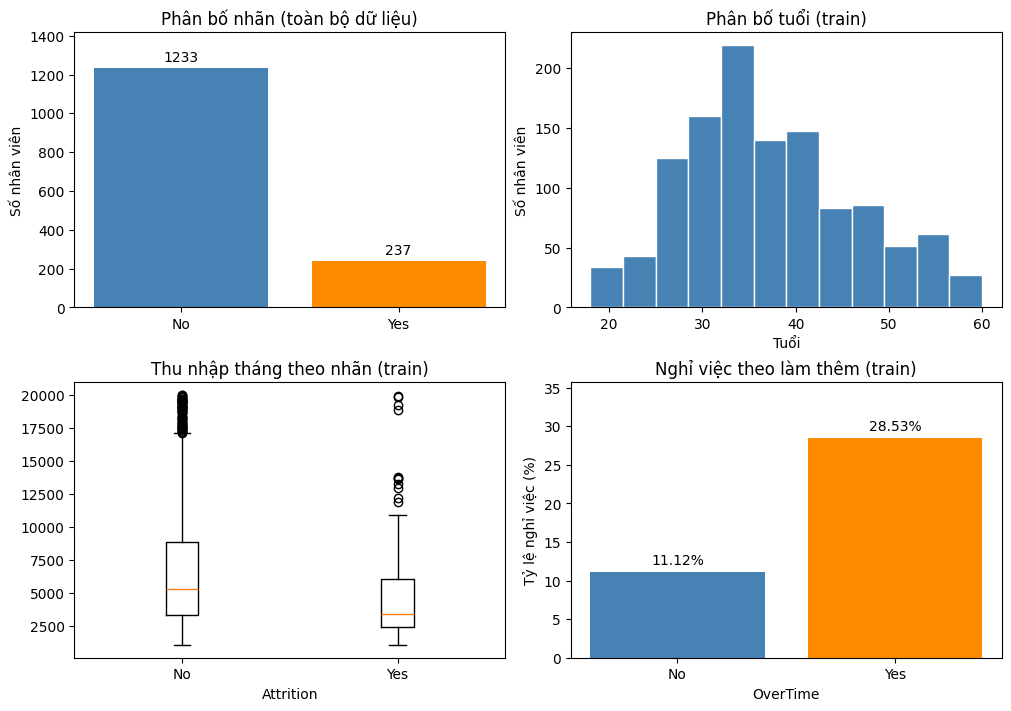

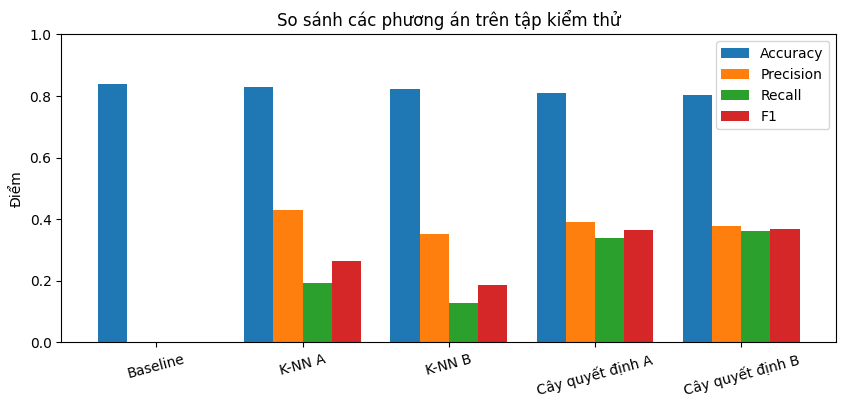

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
# Thống kê các cột số trên tập huấn luyện
cot_so = ["Age", "MonthlyIncome", "YearsAtCompany", "TotalWorkingYears"]
so = X_train[cot_so]
q1, q3 = so.quantile(0.25), so.quantile(0.75)
iqr = q3 - q1

bang_so = so.describe().T
bang_so["Ngoài ngưỡng IQR"] = (
    (so < q1 - 1.5 * iqr) | (so > q3 + 1.5 * iqr)
).sum()
display(bang_so.round(2))

tuong_quan = X_train[cot_so + ["JobLevel"]].corr()
display(tuong_quan.round(2))

# Tỷ lệ nghỉ việc theo tình trạng làm thêm trên tập huấn luyện
train_eda = X_train.assign(Attrition=y_train)
bang_lam_them = train_eda.groupby("OverTime")["Attrition"].agg(
    So_nhan_vien="size", So_ca_nghi="sum"
).reindex(["No", "Yes"])
bang_lam_them["Ty_le_nghi_pct"] = (
    100 * bang_lam_them["So_ca_nghi"] / bang_lam_them["So_nhan_vien"]
)
display(bang_lam_them.round(2))

# Vẽ biểu đồ khám phá dữ liệu
fig, ax = plt.subplots(2, 2, figsize=(10, 7), layout="constrained")

cot = ax[0, 0].bar(so_luong.index, so_luong.values, color=["steelblue", "darkorange"])
ax[0, 0].bar_label(cot, padding=3)
ax[0, 0].set(title="Phân bố nhãn (toàn bộ dữ liệu)",
             ylabel="Số nhân viên", ylim=(0, so_luong.max() * 1.15))

ax[0, 1].hist(so["Age"], bins=12, color="steelblue", edgecolor="white")
ax[0, 1].set(title="Phân bố tuổi (train)", xlabel="Tuổi", ylabel="Số nhân viên")

ax[1, 0].boxplot([
    train_eda.loc[train_eda["Attrition"].eq(0), "MonthlyIncome"],
    train_eda.loc[train_eda["Attrition"].eq(1), "MonthlyIncome"],
])
ax[1, 0].set_xticks([1, 2], ["No", "Yes"])
ax[1, 0].set(title="Thu nhập tháng theo nhãn (train)", xlabel="Attrition")

ty_le = bang_lam_them["Ty_le_nghi_pct"]
cot = ax[1, 1].bar(ty_le.index, ty_le.values, color=["steelblue", "darkorange"])
ax[1, 1].bar_label(cot, fmt="%.2f%%", padding=3)
ax[1, 1].set(title="Nghỉ việc theo làm thêm (train)", xlabel="OverTime",
             ylabel="Tỷ lệ nghỉ việc (%)", ylim=(0, ty_le.max() * 1.25))

fig.savefig("kham_pha_du_lieu.png", dpi=200, bbox_inches="tight")
plt.show()

# Vẽ biểu đồ so sánh các phương án trên tập kiểm thử
ax_diem = bang_test.plot.bar(figsize=(10, 4), rot=15, width=0.8)
ax_diem.set(title="So sánh các phương án trên tập kiểm thử",
            xlabel="", ylabel="Điểm", ylim=(0, 1))
ax_diem.get_figure().savefig("so_sanh_mo_hinh.png", dpi=200, bbox_inches="tight")
plt.show()

# Gộp bảng và hình mới với kết quả đã lưu ở bước 7
bang_so.round(2).to_csv("thong_ke_dac_trung.csv", encoding="utf-8-sig")
tuong_quan.round(3).to_csv("tuong_quan_pearson.csv", encoding="utf-8-sig")
bang_lam_them.round(2).to_csv("nghi_viec_theo_lam_them_train.csv", encoding="utf-8-sig")

ten_goi = "Nhom4_DeTai13_KetQua_DayDu.zip"
with ZipFile(ten_goi, "w", compression=ZIP_DEFLATED) as goi:
    with ZipFile("Nhom4_DeTai13_KetQua.zip") as goi_cu:
        for tep in goi_cu.namelist():
            goi.writestr(tep, goi_cu.read(tep))
    for tep in ["thong_ke_dac_trung.csv", "tuong_quan_pearson.csv",
                "nghi_viec_theo_lam_them_train.csv", "kham_pha_du_lieu.png",
                "so_sanh_mo_hinh.png"]:
        goi.write(tep)

files.download(ten_goi)

In [10]:
chi_tiet_cv = []

for ten, mau_mo_hinh, chuan_hoa, luoi_tham_so in thi_nghiem:
    for luong in ["A", "B"]:
        tao_dac_trung = (
            FunctionTransformer(tao_dac_trung_B)
            if luong == "B" else "passthrough"
        )

        quy_trinh_moi = Pipeline([
            ("dac_trung", tao_dac_trung),
            ("tien_xu_ly", tao_tien_xu_ly(chuan_hoa=chuan_hoa)),
            ("model", mau_mo_hinh),
        ])

        luot_do = GridSearchCV(
            quy_trinh_moi, luoi_tham_so, cv=cv,
            scoring="f1", error_score="raise"
        )
        luot_do.fit(X_train, y_train)

        bang_luot = pd.DataFrame(luot_do.cv_results_)[
            ["params", "mean_test_score", "std_test_score", "rank_test_score"]
        ].copy()
        bang_luot.insert(0, "Phương án", f"{ten} {luong}")
        chi_tiet_cv.append(bang_luot)

bang_chi_tiet_cv = pd.concat(chi_tiet_cv, ignore_index=True).sort_values(
    ["Phương án", "rank_test_score"]
)

print("Tổng số cấu hình:", len(bang_chi_tiet_cv))
display(bang_chi_tiet_cv.groupby("Phương án").size().rename("Số cấu hình"))
display(bang_chi_tiet_cv.groupby("Phương án", sort=False).head(3))

bang_chi_tiet_cv.to_csv(
    "chi_tiet_68_cau_hinh_cv.csv", index=False, encoding="utf-8-sig"
)

Tổng số cấu hình: 68


,Số cấu hình
Phương án,
Cây quyết định A,24
Cây quyết định B,24
K-NN A,10
K-NN B,10


,Phương án,params,mean_test_score,std_test_score,rank_test_score
27,Cây quyết định A,"{'model__class_weight': None, 'model__max_dept...",0.390524,0.053706,1
30,Cây quyết định A,"{'model__class_weight': None, 'model__max_dept...",0.384044,0.034962,2
37,Cây quyết định A,"{'model__class_weight': 'balanced', 'model__ma...",0.380757,0.011984,3
51,Cây quyết định B,"{'model__class_weight': None, 'model__max_dept...",0.406783,0.068894,1
54,Cây quyết định B,"{'model__class_weight': None, 'model__max_dept...",0.394654,0.057520,2
58,Cây quyết định B,"{'model__class_weight': 'balanced', 'model__ma...",0.377595,0.075674,3
0,K-NN A,"{'model__n_neighbors': 3, 'model__weights': 'u...",0.255908,0.114448,1
1,K-NN A,"{'model__n_neighbors': 3, 'model__weights': 'd...",0.255908,0.114448,1
2,K-NN A,"{'model__n_neighbors': 5, 'model__weights': 'u...",0.228191,0.126219,3
10,K-NN B,"{'model__n_neighbors': 3, 'model__weights': 'u...",0.267535,0.082354,1


In [11]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import FunctionTransformer

def bo_mot_ty_le(bang, cot):
    return tao_dac_trung_B(bang).drop(columns=[cot])

bien_the = {
    "B đầy đủ": FunctionTransformer(tao_dac_trung_B),
    "A (bỏ cả 3 tỷ lệ)": "passthrough",
}

for cot in ["CompanyTenureShare", "RoleTenureShare", "PromotionLagShare"]:
    bien_the[f"B bỏ {cot}"] = FunctionTransformer(
        bo_mot_ty_le, kw_args={"cot": cot}
    )

cac_fold = list(cv.split(X_train, y_train))
dong_bo_ty_le = []

for ten in ["K-NN", "Cây quyết định"]:
    for ten_bien_the, buoc_dac_trung in bien_the.items():
        mo_hinh_thu = clone(mo_hinh_da_huan_luyen[f"{ten} B"])
        mo_hinh_thu.set_params(dac_trung=buoc_dac_trung)

        diem = cross_val_score(
            mo_hinh_thu, X_train, y_train,
            cv=cac_fold, scoring="f1", error_score="raise"
        )

        dong_bo_ty_le.append({
            "Thuật toán": ten,
            "Biến thể": ten_bien_the,
            "F1 trung bình": diem.mean(),
            "Độ lệch chuẩn": diem.std(),
        })

bang_bo_ty_le = pd.DataFrame(dong_bo_ty_le)
f1_b = bang_bo_ty_le.loc[
    bang_bo_ty_le["Biến thể"].eq("B đầy đủ")
].set_index("Thuật toán")["F1 trung bình"]

bang_bo_ty_le["Chênh lệch so với B"] = (
    bang_bo_ty_le["F1 trung bình"] - bang_bo_ty_le["Thuật toán"].map(f1_b)
)

display(bang_bo_ty_le.round(4))

bang_bo_ty_le.to_csv(
    "thi_nghiem_bo_tung_ty_le.csv", index=False, encoding="utf-8-sig"
)

,Thuật toán,Biến thể,F1 trung bình,Độ lệch chuẩn,Chênh lệch so với B
0,K-NN,B đầy đủ,0.2675,0.0824,0.0000
1,K-NN,A (bỏ cả 3 tỷ lệ),0.2559,0.1144,-0.0116
2,K-NN,B bỏ CompanyTenureShare,0.2704,0.1064,0.0029
3,K-NN,B bỏ RoleTenureShare,0.2209,0.0645,-0.0467
4,K-NN,B bỏ PromotionLagShare,0.2569,0.0688,-0.0107
5,Cây quyết định,B đầy đủ,0.4068,0.0689,0.0000
6,Cây quyết định,A (bỏ cả 3 tỷ lệ),0.3905,0.0537,-0.0163
7,Cây quyết định,B bỏ CompanyTenureShare,0.3957,0.0609,-0.0111
8,Cây quyết định,B bỏ RoleTenureShare,0.3993,0.0626,-0.0075
9,Cây quyết định,B bỏ PromotionLagShare,0.4108,0.0788,0.0041


In [12]:
cay_day_du = mo_hinh_da_huan_luyen["Cây quyết định B"]
cay = cay_day_du.named_steps["model"]
ten_dac_trung = cay_day_du.named_steps["tien_xu_ly"].get_feature_names_out()

mau_minh_hoa = X_test.loc[[16, 24]]
mau_da_xu_ly = cay_day_du[:-1].transform(mau_minh_hoa)
du_doan_mau = cay_day_du.predict(mau_minh_hoa)
duong_di = cay.decision_path(mau_da_xu_ly)
dong_giai_thich = []

for i, dong in enumerate(mau_minh_hoa.index):
    thuc_te = "Yes" if y_test.loc[dong] == 1 else "No"
    du_doan = "Yes" if du_doan_mau[i] == 1 else "No"
    print(f"Dòng {dong} | Thực tế: {thuc_te} | Dự đoán: {du_doan}")

    cac_nut = duong_di.getrow(i).indices
    for nut in cac_nut:
        vi_tri = cay.tree_.feature[nut]
        if vi_tri < 0:
            continue

        ten = ten_dac_trung[vi_tri].split("__", 1)[-1]
        nguong = cay.tree_.threshold[nut]
        dau = "<=" if cay.tree_.children_left[nut] in cac_nut else ">"

        dong_giai_thich.append({
            "Dòng CSV (từ 0)": dong,
            "Thực tế": thuc_te,
            "Dự đoán": du_doan,
            "Điều kiện": f"{ten} {dau} {nguong:.3f}",
        })

bang_duong_di = pd.DataFrame(dong_giai_thich)
display(bang_duong_di)
bang_duong_di.to_csv(
    "duong_di_hai_ca_sai.csv", index=False, encoding="utf-8-sig"
)

Dòng 16 | Thực tế: No | Dự đoán: Yes
Dòng 24 | Thực tế: Yes | Dự đoán: No


,Dòng CSV (từ 0),Thực tế,Dự đoán,Điều kiện
0,16,No,Yes,TotalWorkingYears > 1.500
1,16,No,Yes,OverTime_No <= 0.500
2,16,No,Yes,MonthlyIncome > 2476.000
3,16,No,Yes,MaritalStatus_Single <= 0.500
4,16,No,Yes,EnvironmentSatisfaction <= 2.500
5,16,No,Yes,Age <= 35.500
6,16,No,Yes,CompanyTenureShare <= 0.882
7,24,Yes,No,TotalWorkingYears > 1.500
8,24,Yes,No,OverTime_No > 0.500
9,24,Yes,No,WorkLifeBalance > 1.500


Đã khóa cấu hình: Hồi quy logistic · luồng B · C=3, trọng số=Đều
Ngưỡng: 0.46 | F1 OOF: 0.6319
Cây gốc trên OOF: 123 ca bỏ sót, 196 lỗi.
Mô hình chọn trên OOF: 87 ca bỏ sót, 120 lỗi.


,Mã,Mô hình,Luồng,Tham số,Ngưỡng,F1 OOF,Recall OOF,FN OOF,FP OOF,Tổng lỗi OOF
1289,42,Hồi quy logistic,B,"C=3, trọng số=Đều",0.46,0.6319,0.5421,87,33,120


Ngưỡng ưu tiên phát hiện: 0.36
Trên OOF: 76 FN, 70 FP.


,Mã,Mô hình,Luồng,Tham số,Ngưỡng,F1 OOF,Recall OOF,FN OOF,FP OOF,Tổng lỗi OOF
1284,42,Hồi quy logistic,B,"C=3, trọng số=Đều",0.36,0.6096,0.6,76,70,146


,Phương án,TN,FP,FN,TP,Tổng lỗi,Accuracy,Precision Yes,Recall Yes,F1 Yes,ROC-AUC,Average Precision
0,Cây quyết định B (gốc),219,28,30,17,58,0.8027,0.3778,0.3617,0.3696,0.6953,0.3595
1,"Mô hình nâng cấp (ngưỡng 0,50)",236,11,31,16,42,0.8571,0.5926,0.3404,0.4324,0.8139,0.5615
2,Mô hình nâng cấp (ngưỡng tối đa F1 OOF),234,13,30,17,43,0.8537,0.5667,0.3617,0.4416,0.8139,0.5615
3,Mô hình nâng cấp (ngưỡng ưu tiên phát hiện),225,22,24,23,46,0.8435,0.5111,0.4894,0.5000,0.8139,0.5615


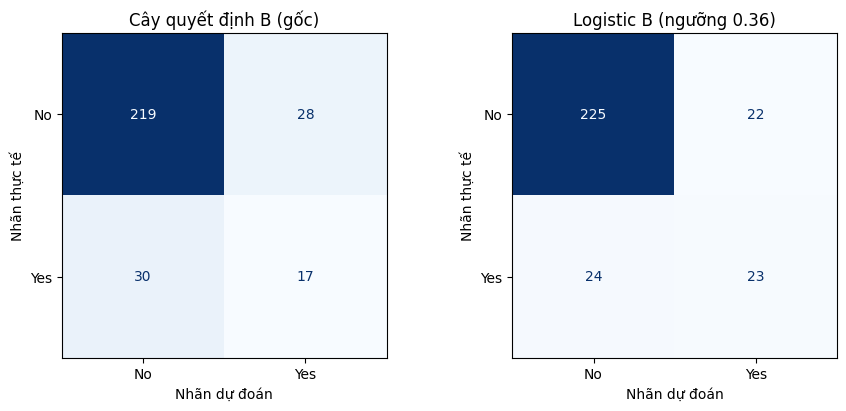

In [17]:
from itertools import product

import numpy as np
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import cross_val_predict
from threadpoolctl import threadpool_limits

# Các cấu hình dùng chung 5 fold của tập huấn luyện.
folds_chon = list(cv.split(X_train, y_train))
y_chon = y_train.to_numpy()
cay_goc = mo_hinh_da_huan_luyen["Cây quyết định B"]
du_doan_goc_cv = cross_val_predict(cay_goc, X_train, y_train, cv=folds_chon)
tn_goc_cv, fp_goc_cv, fn_goc_cv, tp_goc_cv = confusion_matrix(
    y_chon, du_doan_goc_cv, labels=[0, 1]
).ravel()

ung_vien = []
for luong in ("A", "B"):
    for c, w in product((0.03, 0.10, 0.30, 1.0, 3.0), ("Đều", "Gấp đôi", "Cân bằng")):
        trong_so = {"Đều": None, "Gấp đôi": {0: 1, 1: 2}, "Cân bằng": "balanced"}[w]
        ung_vien.append((
            "Hồi quy logistic", luong, True,
            f"C={c:g}, trọng số={w}",
            LogisticRegression(C=c, class_weight=trong_so, max_iter=2000),
        ))
    for la, vong, l2 in product((7, 15), (100, 200), (1.0, 5.0)):
        ung_vien.append((
            "Tăng cường gradient", luong, False,
            f"max_leaf_nodes={la}, max_iter={vong}, l2_regularization={l2:g}",
            HistGradientBoostingClassifier(
                max_leaf_nodes=la, max_iter=vong, l2_regularization=l2,
                early_stopping=False, random_state=42,
            ),
        ))
    for do_sau, mau_la in product((6, 12, None), (4, 10)):
        ung_vien.append((
            "Rừng ngẫu nhiên", luong, False,
            f"max_depth={do_sau}, min_samples_leaf={mau_la}",
            RandomForestClassifier(
                n_estimators=120, max_depth=do_sau, min_samples_leaf=mau_la,
                random_state=42, n_jobs=1,
            ),
        ))

quy_trinh_moi = {}
dong_chon = []
nguong_thu = np.round(np.arange(0.10, 0.701, 0.02), 2)
so_duong = y_chon == 1

# Dự đoán ngoài fold: mỗi mẫu được dự đoán bởi một mô hình chưa thấy mẫu đó.
with threadpool_limits(limits=1):
    for ma, (ten, luong, chuan_hoa, tham_so, mo_hinh) in enumerate(ung_vien, start=1):
        bo_dac_trung = (
            FunctionTransformer(tao_dac_trung_B) if luong == "B" else "passthrough"
        )
        quy_trinh = Pipeline([
            ("dac_trung", bo_dac_trung),
            ("tien_xu_ly", tao_tien_xu_ly(chuan_hoa=chuan_hoa)),
            ("model", mo_hinh),
        ])
        quy_trinh_moi[ma] = quy_trinh
        p_cv = cross_val_predict(
            quy_trinh, X_train, y_train, cv=folds_chon, method="predict_proba"
        )[:, 1]
        for nguong in nguong_thu:
            du_doan_duong = p_cv >= nguong
            tp = int(np.count_nonzero(du_doan_duong & so_duong))
            fp = int(np.count_nonzero(du_doan_duong & ~so_duong))
            fn = int(np.count_nonzero(~du_doan_duong & so_duong))
            dong_chon.append({
                "Mã": ma, "Mô hình": ten, "Luồng": luong, "Tham số": tham_so,
                "Ngưỡng": nguong, "F1 OOF": 2 * tp / (2 * tp + fp + fn),
                "Recall OOF": tp / (tp + fn), "FN OOF": fn, "FP OOF": fp,
                "Tổng lỗi OOF": fp + fn,
            })

bang_chon = pd.DataFrame(dong_chon)
# Chỉ cân nhắc phương án giảm cả bỏ sót và tổng lỗi trên OOF.
du_dieu_kien = bang_chon.loc[
    (bang_chon["FN OOF"] < fn_goc_cv)
    & (bang_chon["Tổng lỗi OOF"] < fp_goc_cv + fn_goc_cv)
]
if du_dieu_kien.empty:
    raise RuntimeError("Không tìm thấy phương án giảm cả hai loại số đếm trên OOF.")

# Chọn F1 dương cao nhất; nếu đồng điểm, ưu tiên ít lỗi rồi dùng thứ tự cố định.
xep_hang = du_dieu_kien.sort_values(
    ["F1 OOF", "Tổng lỗi OOF", "FN OOF", "Mã", "Ngưỡng"],
    ascending=[False, True, True, True, True],
)
chon = xep_hang.iloc[0]
nguong_chon = float(chon["Ngưỡng"])
mo_hinh_nang_cap = clone(quy_trinh_moi[int(chon["Mã"])])
print(f"Đã khóa cấu hình: {chon['Mô hình']} · luồng {chon['Luồng']} · {chon['Tham số']}")
print(f"Ngưỡng: {nguong_chon:.2f} | F1 OOF: {chon['F1 OOF']:.4f}")
print(f"Cây gốc trên OOF: {fn_goc_cv} ca bỏ sót, {fp_goc_cv + fn_goc_cv} lỗi.")
print(f"Mô hình chọn trên OOF: {chon['FN OOF']} ca bỏ sót, {chon['Tổng lỗi OOF']} lỗi.")
display(pd.DataFrame([chon]).round(4))

# Phương án bổ sung: với cùng mô hình, ưu tiên giảm FN nhưng giới hạn FP.
# Dùng số FP ngoài fold của cây gốc làm mức tối đa trong tập huấn luyện.
nguong_kha_dung = bang_chon.loc[
    (bang_chon["Mã"] == chon["Mã"])
    & (bang_chon["FP OOF"] <= fp_goc_cv)
    & (bang_chon["Tổng lỗi OOF"] < fp_goc_cv + fn_goc_cv)
]
chon_uu_tien = nguong_kha_dung.sort_values(
    ["FN OOF", "Tổng lỗi OOF", "Ngưỡng"], ascending=[True, True, True]
).iloc[0]
nguong_uu_tien = float(chon_uu_tien["Ngưỡng"])
print(f"Ngưỡng ưu tiên phát hiện: {nguong_uu_tien:.2f}")
print(f"Trên OOF: {chon_uu_tien['FN OOF']} FN, {chon_uu_tien['FP OOF']} FP.")
display(pd.DataFrame([chon_uu_tien]).round(4))

import json
from pathlib import Path

thu_muc_nang_cap = Path("ket_qua_nang_cap")
thu_muc_nang_cap.mkdir(exist_ok=True)
bang_chon.to_csv(thu_muc_nang_cap / "chon_mo_hinh_oof.csv", index=False, encoding="utf-8-sig")

thong_tin_chon = chon.to_dict()
thong_tin_chon.update(
    FN_goc_OOF=int(fn_goc_cv),
    tong_loi_goc_OOF=int(fn_goc_cv + fp_goc_cv),
    so_cau_hinh=len(ung_vien),
    so_nguong=len(nguong_thu),
    nguong_uu_tien=chon_uu_tien.to_dict(),
)
(thu_muc_nang_cap / "cau_hinh_duoc_chon.json").write_text(
    json.dumps(thong_tin_chon, ensure_ascii=False, indent=2, default=lambda x: x.item()),
    encoding="utf-8",
)


# Chỉ sau khi đã khóa cấu hình và ngưỡng mới chấm trên tập kiểm thử.
with threadpool_limits(limits=1):
    mo_hinh_nang_cap.fit(X_train, y_train)
p_cay_test = cay_goc.predict_proba(X_test)[:, 1]
p_moi_test = mo_hinh_nang_cap.predict_proba(X_test)[:, 1]

def cham_test(ten, du_doan, xac_suat):
    tn, fp, fn, tp = confusion_matrix(y_test, du_doan, labels=[0, 1]).ravel()
    return {
        "Phương án": ten, "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Tổng lỗi": int(fp + fn),
        "Accuracy": accuracy_score(y_test, du_doan),
        "Precision Yes": precision_score(y_test, du_doan, zero_division=0),
        "Recall Yes": recall_score(y_test, du_doan, zero_division=0),
        "F1 Yes": f1_score(y_test, du_doan, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, xac_suat),
        "Average Precision": average_precision_score(y_test, xac_suat),
    }

bang_nang_cap = pd.DataFrame([
    cham_test("Cây quyết định B (gốc)", cay_goc.predict(X_test), p_cay_test),
    cham_test("Mô hình nâng cấp (ngưỡng 0,50)", p_moi_test >= 0.50, p_moi_test),
    cham_test("Mô hình nâng cấp (ngưỡng tối đa F1 OOF)", p_moi_test >= nguong_chon, p_moi_test),
    cham_test("Mô hình nâng cấp (ngưỡng ưu tiên phát hiện)", p_moi_test >= nguong_uu_tien, p_moi_test),
])
display(bang_nang_cap.round(4))
bang_nang_cap.to_csv(thu_muc_nang_cap / "so_sanh_kiem_thu.csv", index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout="constrained")
for ax, ten, du_doan in zip(
    axes, ["Cây quyết định B (gốc)", f"Logistic B (ngưỡng {nguong_uu_tien:.2f})"],
    [cay_goc.predict(X_test), p_moi_test >= nguong_uu_tien],
):
    ConfusionMatrixDisplay.from_predictions(
        y_test, du_doan, labels=[0, 1], display_labels=["No", "Yes"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set(title=ten, xlabel="Nhãn dự đoán", ylabel="Nhãn thực tế")
fig.savefig(thu_muc_nang_cap / "ma_tran_truoc_sau.png", dpi=200, bbox_inches="tight")
plt.show()